# Практическая работа № 6. Классификация текстов
Дисциплина: машинное обучение. Автор: ISLAM (IIDEV1).

**Цель:** сравнить Bag of Words и TF-IDF с наивным байесовским классификатором; реализовать обработку русского текста и сравнить два алгоритма. Выполнены уровни A, B, C.

## Данные и разметка
Самостоятельно сформирована учебная выборка из открытого [RuReviews](https://github.com/sismetanin/rureviews) (S. Smetanin, M. Komarov, 2019; Apache-2.0). Это 3000 реальных русскоязычных отзывов об одежде и аксессуарах — по 1000 для классов `negative`, `neutral`, `positive`. Разметка готовая, получена авторами корпуса на основе пользовательских оценок; вручную тексты не размечались. Оценка покупателя может расходиться с тоном текста, поэтому метки могут содержать шум.

Перед случайным отбором с seed=42 удалены пустые записи, дубли нормализованного текста и тексты с конфликтующими метками. Сохранены исходные номера строк, источник и контрольные суммы в `data/provenance.json`. Нормализация фиксированная и не обучается на данных. Выборка искусственно сбалансирована и не отражает доли классов в реальном магазине.

| Поле | Значение |
|---|---|
| source_row | Номер строки исходного TSV, включая заголовок |
| review | Исходный текст отзыва |
| sentiment | Готовая метка тональности |

В исходном корпусе нейтральный класс записан с опечаткой `neautral`; в учебном CSV название исправлено на `neutral` без изменения смысла метки.

In [1]:
from pathlib import Path
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.feature_extraction.text import CountVectorizer, TfidfVectorizer
from sklearn.naive_bayes import MultinomialNB
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, f1_score, classification_report, ConfusionMatrixDisplay
from preprocessing import clean_text, stem_text, STOP_WORDS

SEED = 42
BASE = Path.cwd()
if not (BASE / 'data/reviews.csv').exists():
    BASE = BASE / 'practice-6'
df = pd.read_csv(BASE / 'data/reviews.csv')
RESULTS = BASE / 'results'
RESULTS.mkdir(exist_ok=True)
display(df.head())
display(df.groupby('sentiment').size().rename('Количество').to_frame())
print('Размер корпуса:', df.shape)
assert len(df) >= 500 and df.isna().sum().sum() == 0

assert set(df.sentiment) == {'negative','neutral','positive'}

,source_row,review,sentiment
0,9808,"У меня грудь 101, заказала Xl, оказалось мало,...",negative
1,8505,Продавец хотел обмануть! Товар я не получила п...,negative
2,17383,Товар не пришёл. Продавец не продлил срок защиты.,negative
3,46398,"чулки ничего,но до колен!это не чулки а носки!",neutral
4,75092,"Пришло быстро, быстрее чем мое такое первое. П...",positive


,Количество
sentiment,
negative,1000
neutral,1000
positive,1000


Размер корпуса: (3000, 3)


## Предобработка (B, C)
Переводим текст в нижний регистр, заменяем `ё` на `е`, удаляем цифры и пунктуацию регулярным выражением, токенизируем и удаляем фиксированные русские стоп-слова. Отрицания **не, ни, нет, без** сохраняем: они влияют на тональность. Затем используем русский Snowball-стеммер, чтобы объединить словоформы. Это стемминг, а не лемматизация: получаются основы, а не обязательно существующие слова. Минусы очистки — потеря смайликов, оценок цифрами и эмоциональной пунктуации.

In [2]:
examples = pd.DataFrame({'Исходный текст': df.review.head(5)})
examples['После очистки'] = examples['Исходный текст'].map(clean_text)
examples['После стемминга'] = examples['Исходный текст'].map(stem_text)
display(examples)
print('Проверка отрицаний:', clean_text('НЕ хороший товар! Нет качества, размер 42.'))
assert 'не' in clean_text('НЕ хороший').split()
assert clean_text('Привет, 123!') == 'привет'


,Исходный текст,После очистки,После стемминга
0,"У меня грудь 101, заказала Xl, оказалось мало,...",грудь заказала xl оказалось мало грудь торчит ...,груд заказа xl оказа мал груд торч чашк целик ...
1,Продавец хотел обмануть! Товар я не получила п...,продавец хотел обмануть товар не получила акци...,продавец хотел обманут товар не получ акц алиэ...
2,Товар не пришёл. Продавец не продлил срок защиты.,товар не пришел продавец не продлил срок защиты,товар не пришел продавец не продл срок защит
3,"чулки ничего,но до колен!это не чулки а носки!",чулки ничего колен не чулки носки,чулк нич кол не чулк носк
4,"Пришло быстро, быстрее чем мое такое первое. П...",пришло быстро быстрее такое первое покупала по...,пришл быстр быстр так перв покупа подарок


Проверка отрицаний: не хороший товар нет качества размер


## Разбиение и защита от утечки
Train/test = 80/20, стратификация по классам, random_state=42. Словарь, частоты документов и IDF обучаются только на train внутри `Pipeline`. Используем одинаковое разбиение для всех моделей. Параметры зафиксированы заранее; подбор по test не выполняется. Удаление дублей до разбиения препятствует попаданию одинаковых нормализованных отзывов в обе части.

In [3]:
X_train, X_test, y_train, y_test = train_test_split(
    df.review, df.sentiment, test_size=0.2, random_state=SEED, stratify=df.sentiment)
assert set(X_train.map(stem_text)).isdisjoint(set(X_test.map(stem_text)))
display(pd.DataFrame({'train':y_train.value_counts(), 'test':y_test.value_counts()}))
print('Train:', len(X_train), 'Test:', len(X_test))


,train,test
sentiment,,
negative,800,200
neutral,800,200
positive,800,200


Train: 2400 Test: 600


## A. Bag of Words против TF-IDF
Сравниваем MultinomialNB с одинаковой обработкой и словарными ограничениями: `min_df=2`, `max_df=0.95`, униграммы и биграммы. Редкие слова отсекаются, слишком частые не несут различительной информации. Биграммы помогают различать «хороший» и «не хороший» (после стемминга). `alpha=1.0` задаёт сглаживание.

## C. Второй алгоритм
Логистическая регрессия обучается на таком же TF-IDF пространстве. Accuracy — доля верных ответов; macro-F1 — среднее F1 по классам с одинаковым весом каждого класса. Последняя метрика помогает не скрывать слабое распознавание нейтральных отзывов.

In [4]:
vector_args = dict(preprocessor=stem_text, lowercase=False,
                   token_pattern=r'(?u)\b\w+\b', min_df=2, max_df=0.95, ngram_range=(1,2))
models = {
    'BoW + NB': Pipeline([('vectorizer', CountVectorizer(**vector_args)), ('model', MultinomialNB(alpha=1.0))]),
    'TF-IDF + NB': Pipeline([('vectorizer', TfidfVectorizer(**vector_args)), ('model', MultinomialNB(alpha=1.0))]),
    'TF-IDF + LogisticRegression': Pipeline([('vectorizer', TfidfVectorizer(**vector_args)),
                                           ('model', LogisticRegression(max_iter=2000, random_state=SEED))]),
}
rows, predictions = [], {}
for name, model in models.items():
    model.fit(X_train, y_train)
    predictions[name] = model.predict(X_test)
    rows.append({'Модель':name, 'Accuracy':accuracy_score(y_test, predictions[name]),
                 'F1 macro':f1_score(y_test, predictions[name], average='macro'),
                 'Признаков':len(model.named_steps['vectorizer'].vocabulary_)})
metrics = pd.DataFrame(rows).set_index('Модель')
display(metrics.round(4))
metrics.to_csv(RESULTS / 'metrics.csv')
assert models['TF-IDF + NB']['vectorizer'].vocabulary_ == models['TF-IDF + LogisticRegression']['vectorizer'].vocabulary_
for name in models:
    print('\n', name)
    print(classification_report(y_test, predictions[name], digits=4, zero_division=0))


,Accuracy,F1 macro,Признаков
Модель,,,
BoW + NB,0.6817,0.6799,5640
TF-IDF + NB,0.6850,0.6816,5640
TF-IDF + LogisticRegression,0.7050,0.7047,5640



 BoW + NB
              precision    recall  f1-score   support

    negative     0.6704    0.6000    0.6332       200
     neutral     0.5625    0.5850    0.5735       200
    positive     0.8075    0.8600    0.8329       200

    accuracy                         0.6817       600
   macro avg     0.6801    0.6817    0.6799       600
weighted avg     0.6801    0.6817    0.6799       600


 TF-IDF + NB
              precision    recall  f1-score   support

    negative     0.6667    0.6300    0.6478       200
     neutral     0.5781    0.5550    0.5663       200
    positive     0.7945    0.8700    0.8305       200

    accuracy                         0.6850       600
   macro avg     0.6798    0.6850    0.6816       600
weighted avg     0.6798    0.6850    0.6816       600


 TF-IDF + LogisticRegression
              precision    recall  f1-score   support

    negative     0.6816    0.6850    0.6833       200
     neutral     0.6010    0.5950    0.5980       200
    positive     0.8

На этом test максимальный macro-F1 среди байесовских вариантов у **TF-IDF + NB**: **0.6816**. Это результат одного разбиения, а не доказательство общего превосходства метода.

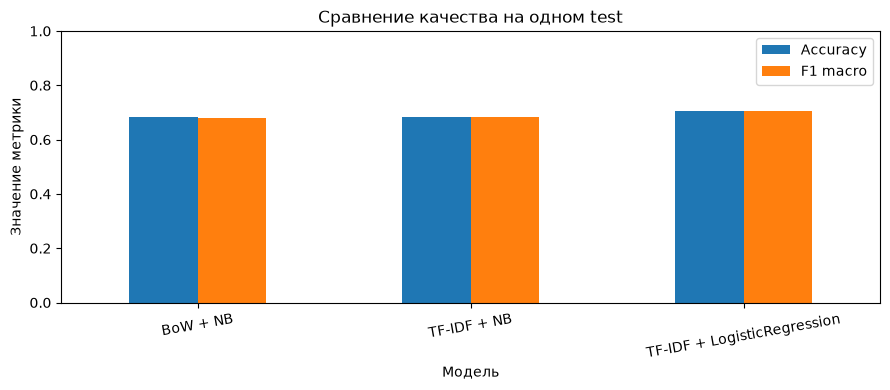

In [5]:
nb_results = metrics.loc[['BoW + NB', 'TF-IDF + NB']]
winner = nb_results['F1 macro'].idxmax()
display(Markdown(f"На этом test максимальный macro-F1 среди байесовских вариантов у **{winner}**: "
                 f"**{nb_results.loc[winner, 'F1 macro']:.4f}**. "
                 "Это результат одного разбиения, а не доказательство общего превосходства метода."))
fig, ax = plt.subplots(figsize=(9,4))
metrics[['Accuracy','F1 macro']].plot.bar(ax=ax, ylim=(0,1), rot=10)
ax.set(title='Сравнение качества на одном test', ylabel='Значение метрики', xlabel='Модель')
fig.tight_layout()
fig.savefig(RESULTS/'metrics.png', dpi=150)
plt.show()


График сравнивает точность и macro-F1 трёх моделей при одинаковых текстах обучения и проверки. Разница между метриками связана с неодинаковым качеством по классам, даже при равном количестве примеров. Надёжность различий требует нескольких разбиений или кросс-валидации на train.

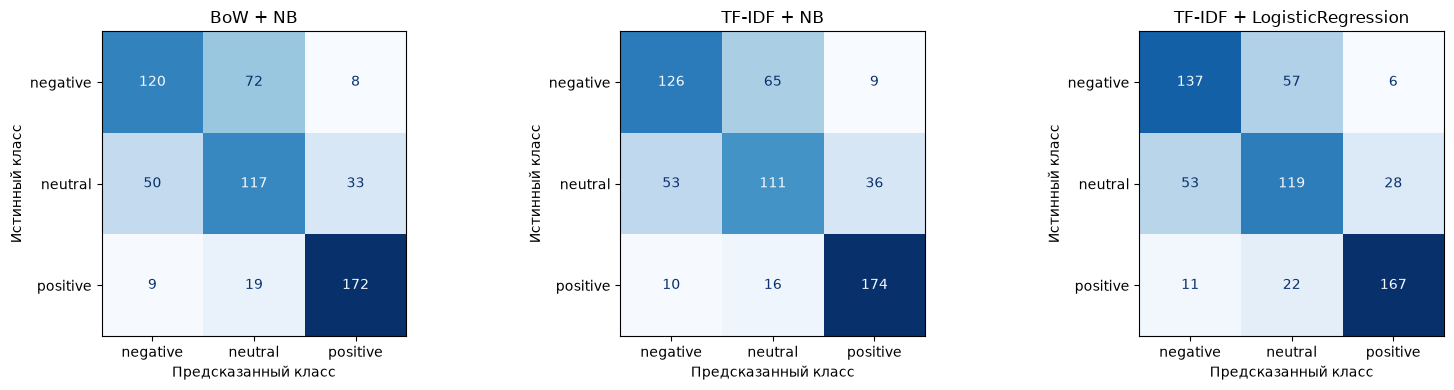

In [6]:
fig, axes = plt.subplots(1,3,figsize=(16,4))
for ax, (name, pred) in zip(axes, predictions.items()):
    ConfusionMatrixDisplay.from_predictions(y_test, pred, labels=['negative','neutral','positive'],
                                           ax=ax, colorbar=False, cmap='Blues')
    ax.set(title=name, xlabel='Предсказанный класс', ylabel='Истинный класс')
    assert int(ax.images[0].get_array().sum()) == len(y_test)
fig.tight_layout()
fig.savefig(RESULTS/'confusion_matrices.png', dpi=150)
plt.show()


В матрицах диагональ показывает верные ответы, остальные ячейки — направления ошибок. Нейтральный класс семантически пограничный: отзыв может одновременно хвалить товар и критиковать доставку. Конкретные ошибочные тексты рассмотрены ниже. У TF-IDF + NB верно распознаны 126/200 отрицательных, 111/200 нейтральных и 174/200 положительных отзывов: нейтральный класс действительно оказался самым сложным.

## B. Разбор пяти ошибок
Для анализа заранее выбран TF-IDF + NB, независимо от его места в сравнении. Берём первые пять неверных предсказаний в фиксированном порядке test. Комментарии — гипотезы, а не установленные причины; анализ test не используется для переобучения.

In [7]:
error_df = pd.DataFrame({'Текст':X_test, 'Истинный класс':y_test,
                         'Прогноз':predictions['TF-IDF + NB']})
error_df = error_df[error_df['Истинный класс'] != error_df['Прогноз']].head(5).copy()
assert len(error_df) == 5
display(error_df)
error_df.to_csv(RESULTS/'errors.csv', index=False)


,Текст,Истинный класс,Прогноз
2413,"За такие деньги платье нормально, единственное...",neutral,positive
1725,Я заказывала яркий зеленый. Цвет не соответств...,negative,positive
2383,Не однозначное платье))) очень большие вырезы....,positive,negative
1716,"Заказала xl на свой 42-44 . Но бирок, ничего.",negative,neutral
2380,"цвет скорее не белый, а грязно белый, не соот...",negative,neutral


1. **«За такие деньги платье нормально…»: neutral → positive.** Умеренно положительная оценка сочетается с проблемами длины рукавов и размера. Модель могла переоценить «нормально» и общий ценовой контекст; словарная модель плохо объединяет разнонаправленные суждения.
2. **Зелёный цвет: negative → positive.** Похвала «доставка быстрая» соседствует с жалобами «цвет тухлый, блёклый». Редкие обозначения оттенка могли отсутствовать в словаре или иметь слабый вес, тогда как частая похвала доставке усилила положительный класс.
3. **«Не однозначное платье… своих денег не стоит»: positive → negative.** Прогноз соответствует явной отрицательной оценке в тексте. Возможен шум автоматической метки или несоответствие пользовательской оценки содержанию отзыва; нельзя считать любую такую ошибку недостатком модели.
4. **«Заказала xl… Но бирок, ничего»: negative → neutral.** Короткий текст выражает недовольство косвенно — через отсутствие бирок. После удаления цифр и служебных слов остаётся мало контекста. Модель могла трактовать текст как нейтральное описание заказа.
5. **Грязно-белый цвет и долгая доставка: negative → neutral.** Здесь отрицания сохранены, но обороты «не соответствует цвету» и «не довольна» могут иметь недостаточные веса. Словарные биграммы и независимость признаков в NB ограничивают понимание отрицания и общего смысла нескольких жалоб.

Это гипотезы по прочтению текстов. Для проверки нужны анализ вкладов признаков и отдельные эксперименты на train/validation; после этого разбора модели не переобучались.

## Итог
Построены воспроизводимые пайплайны русского текста: очистка → токенизация → стемминг → BoW/TF-IDF → классификатор. Выполнено сравнение способов векторизации и алгоритмов, выведены размерности и метрики, показаны реальные ошибки.

Ограничения: небольшой сбалансированный подкорпус одной товарной категории, шум автоматических меток, потеря эмоциональных знаков и контекста, отсутствие разделения по автору/товару (их идентификаторов нет). Нет оснований переносить метрики на весь поток отзывов. Следующие эксперименты — символьные n-граммы и сохранение смайликов, с выбором параметров через CV только на train и последующей проверкой на новом отложенном наборе.

**Полученный результат:** 5640 признаков; лучший macro-F1 на этом разбиении у TF-IDF + LogisticRegression — 0.7047 (accuracy 0.7050). Среди двух байесовских вариантов TF-IDF немного выше BoW по macro-F1 (0.6816 против 0.6799), но разница мала и требует проверки на других разбиениях.